# Final result

Global matching, the test evaluation and the group sizes of each round.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
PAIRS = ["wikidata-ror", "deqar-ror"]

In [2]:
final = pd.read_csv("results/final.csv")
final[["round", "pair", "matcher", "split", "P", "R", "F1", "corr"]]

,round,pair,matcher,split,P,R,F1,corr
0,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + no global ma...,validation,1.000,0.876,0.934,133694
1,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + greedy one-t...,validation,1.000,0.817,0.899,16405
2,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + stable matching,validation,1.000,0.824,0.903,14722
3,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + maximum bipa...,validation,1.000,0.150,0.261,18074
4,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + none,test,1.000,0.905,0.950,133694
5,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + no global ma...,validation,1.000,0.664,0.798,72191
6,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + greedy one-t...,validation,1.000,0.612,0.759,6094
7,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + stable matching,validation,1.000,0.612,0.759,5670
8,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + maximum bipa...,validation,1.000,0.033,0.064,6448
9,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + none,test,1.000,0.679,0.809,72191


## Global matching (validation labels)

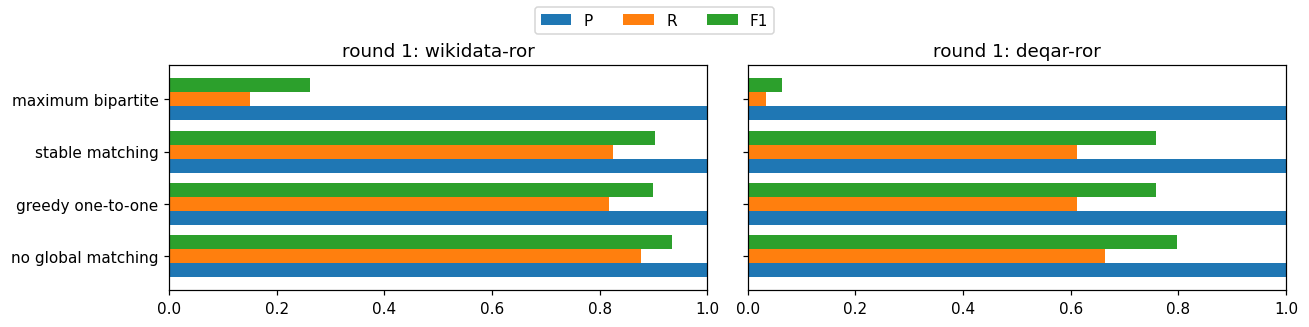

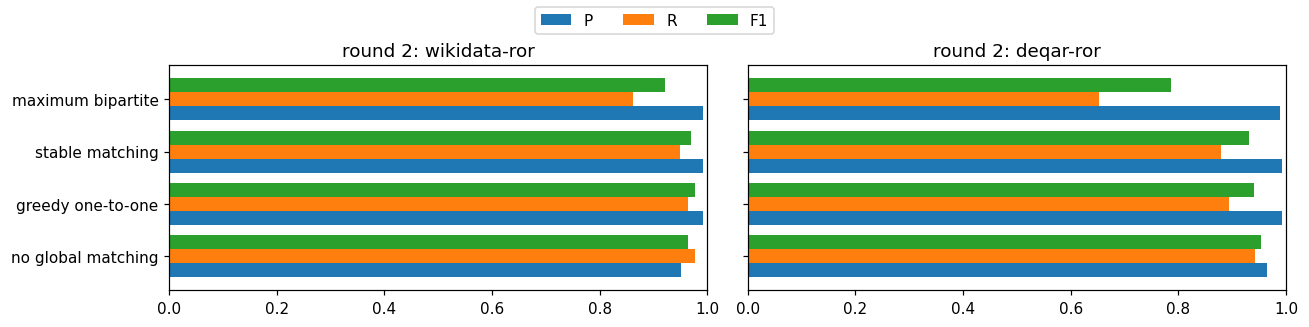

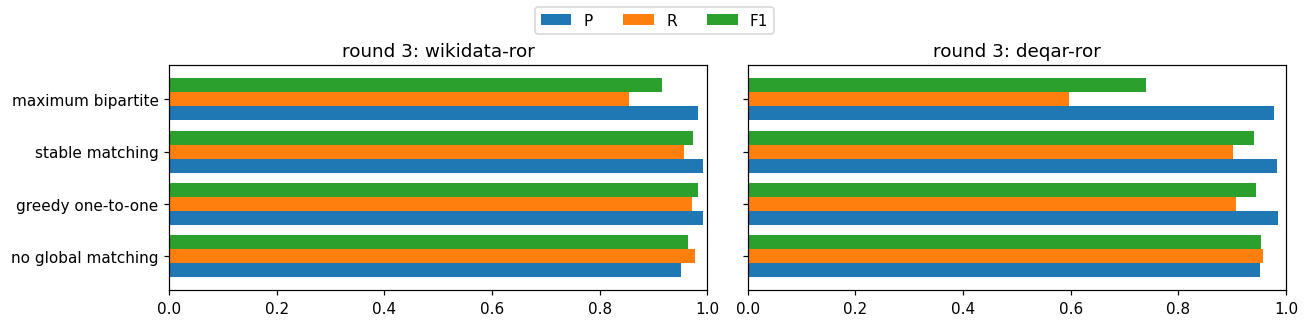

In [3]:
val = final[final["split"] == "validation"].copy()
val["global"] = val["matcher"].str.split(" \\+ ").str[-1]
for rnd in sorted(val["round"].unique()):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
    for ax, pair in zip(axes, PAIRS):
        part = val[(val["round"] == rnd) & (val["pair"] == pair)].set_index("global")[["P", "R", "F1"]]
        part.plot.barh(ax=ax, width=0.8, legend=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"round {rnd}: {pair}")
        ax.set_ylabel("")
    fig.legend(["P", "R", "F1"], loc="upper center", ncol=3)
    plt.tight_layout(rect=(0, 0, 1, 0.93))

## Test result of each round

The test labels are only used once per round, for the final choice.

,round,pair,matcher,P,R,F1,corr
4,1,wikidata-ror,name Levenshtein 0.5 + year 0.5 + none,1.000,0.905,0.950,133694
9,1,deqar-ror,name Levenshtein 0.7 + year 0.3 + none,1.000,0.679,0.809,72191
14,2,wikidata-ror,logistic regression + greedy one-to-one,0.982,0.886,0.932,14898
19,2,deqar-ror,random forest + none,0.885,0.935,0.909,19354
24,3,wikidata-ror,logistic regression + greedy one-to-one,0.982,0.894,0.936,14824
29,3,deqar-ror,random forest + greedy one-to-one,0.991,0.894,0.940,4714


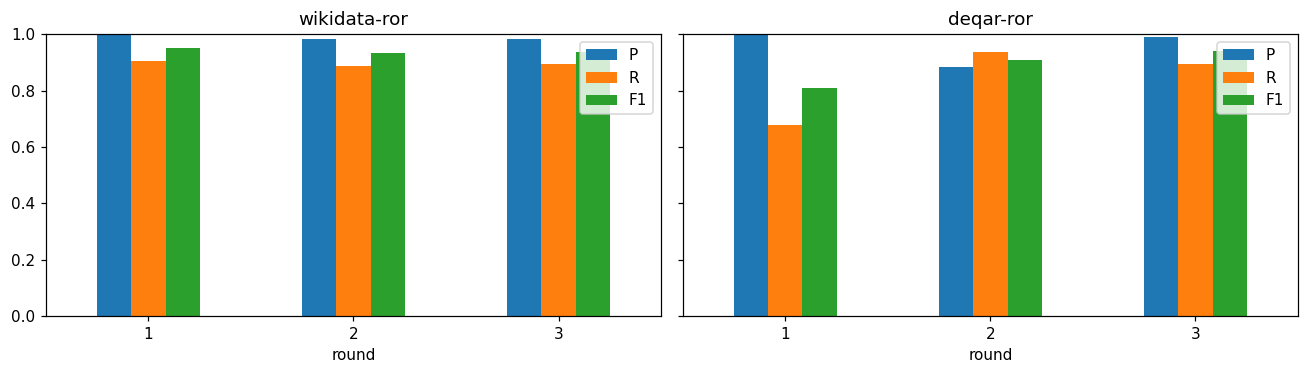

In [4]:
test = final[final["split"] == "test"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, pair in zip(axes, PAIRS):
    test[test["pair"] == pair].set_index("round")[["P", "R", "F1"]].plot.bar(ax=ax, rot=0)
    ax.set_ylim(0, 1)
    ax.set_title(pair)
plt.tight_layout()
test[["round", "pair", "matcher", "P", "R", "F1", "corr"]]

## Group size distribution

With duplicate-free sources a group should have at most 3 records (one per source).

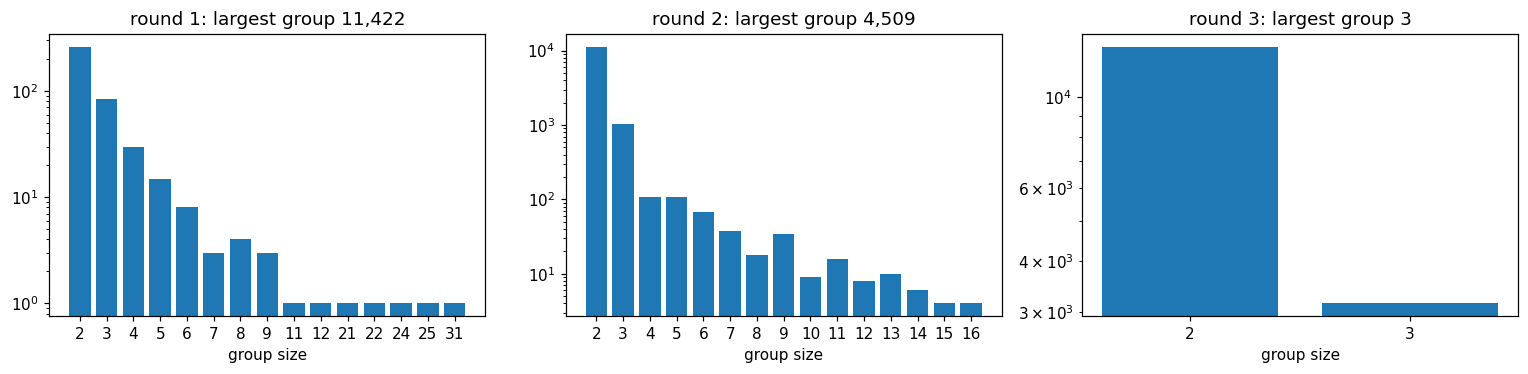

In [5]:
from pathlib import Path

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, rnd in zip(axes, [1, 2, 3]):
    path = Path(f"results/group_sizes_r{rnd}.csv")
    if not path.exists():
        continue
    sizes = pd.read_csv(path)
    ax.bar(sizes["cluster_size"].astype(str).head(15), sizes["frequency"].head(15))
    ax.set_yscale("log")
    ax.set_title(f"round {rnd}: largest group {sizes['cluster_size'].max():,}")
    ax.set_xlabel("group size")
plt.tight_layout()